# Data Profiling & Quality Risk Analysis
## Workshop-2: Building a Reliable Batch Data Pipeline
**Course:** ETL (G01) — Faculty of Engineering and Basic Sciences (UAO)  
**Objective:** Systematic evidence gathering on raw input sources (Spotify and Grammy Awards) to justify Great Expectations quality rules, validation gates, and engineering transformation logic.

---
### Minimum Analysis Categories (Section 6.3):
1. **Structure:** Schemas, columns, row counts, data types.
2. **Completeness:** Missing-value counts and percentages interpreted in context.
3. **Uniqueness and Duplication:** Candidate keys, duplicate patterns, and grain analysis.
4. **Categorical Content:** Cardinality, unexpected labels, frequency patterns.
5. **Numerical Content:** Ranges, distributions, impossible values, extreme outliers.
6. **Temporal Content:** Date coverage, parseability, temporal gaps.
7. **Cross-source Consistency:** Integration contract matching feasibility.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Profiling dependencies loaded successfully.")


Profiling dependencies loaded successfully.


## 1. Raw Data Ingestion

In [2]:
# Ingest datasets
df_spotify = pd.read_csv("../data/spotify_dataset.csv")
df_grammy = pd.read_csv("../data/the_grammy_awards.csv")

print(f"Spotify Dimensions: {df_spotify.shape[0]:,} rows, {df_spotify.shape[1]} columns")
print(f"Grammys Dimensions: {df_grammy.shape[0]:,} rows, {df_grammy.shape[1]} columns")


Spotify Dimensions: 114,000 rows, 21 columns
Grammys Dimensions: 4,810 rows, 10 columns


## 2. Structure & Data Types Analysis

In [3]:
print("=== SPOTIFY STRUCTURE ===")
display(df_spotify.dtypes.to_frame("Data Type"))

print("\n=== GRAMMYS STRUCTURE ===")
display(df_grammy.dtypes.to_frame("Data Type"))


=== SPOTIFY STRUCTURE ===


,Data Type
Unnamed: 0,int64
track_id,object
artists,object
album_name,object
track_name,object
popularity,int64
duration_ms,int64
explicit,bool
danceability,float64
energy,float64



=== GRAMMYS STRUCTURE ===


,Data Type
year,int64
title,object
published_at,object
updated_at,object
category,object
nominee,object
artist,object
workers,object
img,object
winner,bool


## 3. Completeness Analysis (Missing Values)

In [4]:
# Spotify missing values
null_spotify = pd.DataFrame({
    "Null Count": df_spotify.isnull().sum(),
    "Null %": (df_spotify.isnull().sum() / len(df_spotify)) * 100
})
print("Spotify Missing Values:")
display(null_spotify[null_spotify["Null Count"] > 0])

# Grammys missing values
null_grammy = pd.DataFrame({
    "Null Count": df_grammy.isnull().sum(),
    "Null %": (df_grammy.isnull().sum() / len(df_grammy)) * 100
})
print("Grammys Missing Values:")
display(null_grammy[null_grammy["Null Count"] > 0])


Spotify Missing Values:


,Null Count,Null %
artists,1,0.000877
album_name,1,0.000877
track_name,1,0.000877


Grammys Missing Values:


,Null Count,Null %
nominee,6,0.124740
artist,1840,38.253638
workers,2190,45.530146
img,1367,28.419958


## 4. Uniqueness, Candidate Keys & Grain Analysis

In [5]:
print("=== SPOTIFY UNIQUENESS ===")
total_rows = len(df_spotify)
unique_tracks = df_spotify["track_id"].nunique()
dup_track_ids = df_spotify["track_id"].duplicated().sum()
dup_track_genre = df_spotify.duplicated(subset=["track_id", "track_genre"]).sum()

print(f"Total Rows: {total_rows:,}")
print(f"Unique track_ids: {unique_tracks:,}")
print(f"Rows with repeated track_id: {dup_track_ids:,} (tracks appearing in multiple genres)")
print(f"Exact Duplicate Tuples (track_id, track_genre): {dup_track_genre}")

print("\n=== GRAMMYS UNIQUENESS ===")
dup_grammy_natural = df_grammy.duplicated(subset=["year", "category", "nominee"]).sum()
print(f"Natural Key Duplicates (year, category, nominee): {dup_grammy_natural}")


=== SPOTIFY UNIQUENESS ===
Total Rows: 114,000
Unique track_ids: 89,741
Rows with repeated track_id: 24,259 (tracks appearing in multiple genres)
Exact Duplicate Tuples (track_id, track_genre): 450

=== GRAMMYS UNIQUENESS ===
Natural Key Duplicates (year, category, nominee): 0


## 5. Categorical Content Analysis

In [6]:
print(f"Total distinct Spotify genres: {df_spotify['track_genre'].nunique()}")
print(f"Top 10 Genres by Track Count:\n{df_spotify['track_genre'].value_counts().head(10)}")

print(f"\nTotal Grammy Award Categories: {df_grammy['category'].nunique()}")
print(f"Winner Indicator Distribution:\n{df_grammy['winner'].value_counts()}")


Total distinct Spotify genres: 114
Top 10 Genres by Track Count:
track_genre
acoustic             1000
punk-rock            1000
progressive-house    1000
power-pop            1000
pop                  1000
pop-film             1000
piano                1000
party                1000
pagode               1000
opera                1000
Name: count, dtype: int64

Total Grammy Award Categories: 638
Winner Indicator Distribution:
winner
True    4810
Name: count, dtype: int64


## 6. Numerical Content & Boundary Analysis

In [7]:
num_cols = ["popularity", "duration_ms", "danceability", "energy", "loudness", "valence", "tempo"]
display(df_spotify[num_cols].describe().round(3))

# Detection of physically impossible values
zero_duration = (df_spotify["duration_ms"] <= 1000).sum()
zero_tempo = (df_spotify["tempo"] == 0).sum()
print(f"Tracks with duration <= 1,000 ms: {zero_duration}")
print(f"Tracks with tempo == 0 BPM: {zero_tempo}")


,popularity,duration_ms,danceability,energy,loudness,valence,tempo
count,114000.000,114000.000,114000.000,114000.000,114000.000,114000.000,114000.000
mean,33.239,228029.153,0.567,0.641,-8.259,0.474,122.148
std,22.305,107297.713,0.174,0.252,5.029,0.259,29.978
min,0.000,0.000,0.000,0.000,-49.531,0.000,0.000
25%,17.000,174066.000,0.456,0.472,-10.013,0.260,99.219
50%,35.000,212906.000,0.580,0.685,-7.004,0.464,122.017
75%,50.000,261506.000,0.695,0.854,-5.003,0.683,140.071
max,100.000,5237295.000,0.985,1.000,4.532,0.995,243.372


Tracks with duration <= 1,000 ms: 1
Tracks with tempo == 0 BPM: 157


## 7. Temporal Content Analysis

In [8]:
print(f"Grammy Year Range: {df_grammy['year'].min()} to {df_grammy['year'].max()}")
print(f"Total award years covered: {df_grammy['year'].nunique()}")

# Parsing ISO timestamps with mixed offsets
df_grammy["pub_parsed"] = pd.to_datetime(df_grammy["published_at"], utc=True, errors="coerce")
invalid_dates = df_grammy["pub_parsed"].isnull().sum()
print(f"Unparseable timestamps in published_at: {invalid_dates}")


Grammy Year Range: 1958 to 2019
Total award years covered: 62
Unparseable timestamps in published_at: 0


## 8. Cross-Source Consistency & Integration Matching

In [9]:
# Exact title match baseline test
spotify_titles = df_spotify["track_name"].dropna().str.lower().str.strip()
grammy_nominees = df_grammy["nominee"].dropna().str.lower().str.strip()

exact_title_matches = len(set(spotify_titles).intersection(set(grammy_nominees)))
print(f"Direct song title matches: {exact_title_matches:,}")

# Artist formatting difference demonstration
print("\nArtist format difference:")
print("Spotify:", df_spotify["artists"].iloc[2])
print("Grammys:", df_grammy[df_grammy["artist"].notnull()]["artist"].iloc[0])


Direct song title matches: 706

Artist format difference:
Spotify: Ingrid Michaelson;ZAYN
Grammys: Billie Eilish


## 8b. Figures supporting the reported risks
The figures below are generated from the raw files (nothing is modified) and back the risks in section 9.

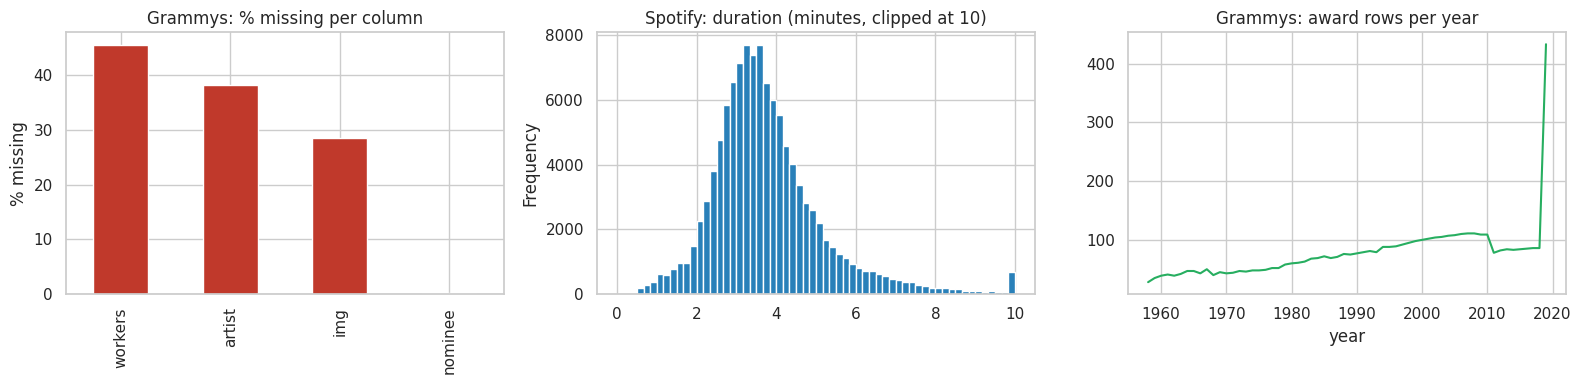

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
# Completeness (Grammys) - RISK: null artist / nominee
null_g = df_grammy.isnull().mean().mul(100).sort_values(ascending=False)
null_g[null_g > 0].plot.bar(ax=axes[0], color="#c0392b")
axes[0].set_title("Grammys: % missing per column")
axes[0].set_ylabel("% missing")
# Duration distribution (Spotify) - RISK: impossible durations
df_spotify["duration_ms"].div(60000).clip(upper=10).plot.hist(bins=60, ax=axes[1], color="#2980b9")
axes[1].set_title("Spotify: duration (minutes, clipped at 10)")
# Award years coverage - RISK: temporal coverage of RQ-03
df_grammy["year"].value_counts().sort_index().plot(ax=axes[2], color="#27ae60")
axes[2].set_title("Grammys: award rows per year")
plt.tight_layout(); plt.show()

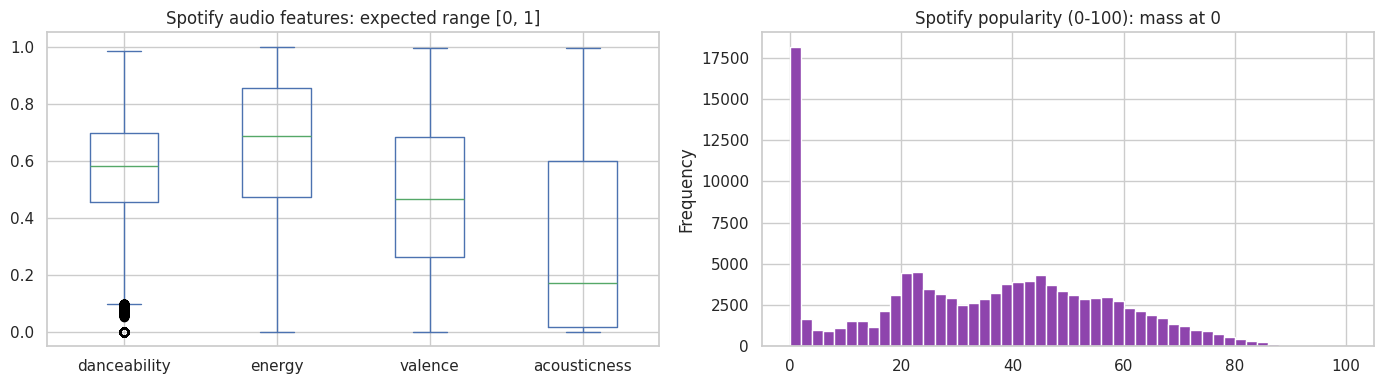

Rows with popularity == 0: 16020


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df_spotify[["danceability", "energy", "valence", "acousticness"]].plot.box(ax=axes[0])
axes[0].set_title("Spotify audio features: expected range [0, 1]")
df_spotify["popularity"].plot.hist(bins=50, ax=axes[1], color="#8e44ad")
axes[1].set_title("Spotify popularity (0-100): mass at 0")
plt.tight_layout(); plt.show()
print("Rows with popularity == 0:", (df_spotify["popularity"] == 0).sum())

## 8c. Cross-source matching: raw vs normalized key
Measures how many Grammy (work, artist) pairs find a Spotify track with the raw text versus the normalized key used by `src/transform.py` (TR-04/TR-05). This is the evidence behind the integration contract.

In [12]:
import re

def norm(t):
    if pd.isna(t):
        return ""
    t = re.sub(r"[\"'\(\)\[\],.;:!?\-]", " ", str(t).lower().strip())
    return re.sub(r"\s+", " ", t).strip()

def primary(a):
    if pd.isna(a):
        return "Unknown Artist"
    a = str(a).split(";")[0]
    return re.split(r"\b(featuring|feat\.|&|with)\b", a, flags=re.IGNORECASE)[0].strip()

g = df_grammy.dropna(subset=["nominee"])
s = df_spotify.dropna(subset=["track_name", "artists"])
raw_keys_g = set(zip(g["nominee"].str.lower().str.strip(), g["artist"].fillna("").str.lower().str.strip()))
raw_keys_s = set(zip(s["track_name"].str.lower().str.strip(), s["artists"].str.lower().str.strip()))
norm_keys_g = set(zip(g["nominee"].map(norm), g["artist"].map(primary).map(norm)))
norm_keys_s = set(zip(s["track_name"].map(norm), s["artists"].map(primary).map(norm)))
summary = pd.DataFrame({
    "Grammy keys": [len(raw_keys_g), len(norm_keys_g)],
    "Matched keys": [len(raw_keys_g & raw_keys_s), len(norm_keys_g & norm_keys_s)],
}, index=["raw text", "normalized (TR-04/05)"])
summary["Match rate %"] = (summary["Matched keys"] / summary["Grammy keys"] * 100).round(2)
display(summary)
print("Grammy rows with null artist (cannot match on artist):", df_grammy["artist"].isna().sum())

,Grammy keys,Matched keys,Match rate %
raw text,4446,161,3.62
normalized (TR-04/05),4438,181,4.08


Grammy rows with null artist (cannot match on artist): 1840


## 9. Profiling Synthesis & Quality Risk Matrix

Each risk is backed by an output cell above and becomes a rule in `docs/quality_rules.md`.

| Dataset / Attribute | Profiling Evidence (cell) | Potential Quality Risk | Rule ID · Severity | Related Req. |
| :--- | :--- | :--- | :--- | :--- |
| `spotify` schema | 21 columns incl. all RQ attributes (section 2) | A missing column breaks every downstream step | DQ-RAW-SPT-05 · Critical | RQ-01..03 |
| `spotify.track_id` | 0 nulls; 89,741 distinct ids in 114,000 rows (section 4) | Null key breaks `dim_track` | DQ-RAW-SPT-01 · Critical | RQ-01, RQ-02 |
| `spotify.(track_id, track_genre)` | 450 duplicate rows = 0.39% (section 4) | Double counting in genre KPIs | DQ-RAW-SPT-06 · Warning (removed by TR-03) | RQ-02 |
| `spotify.duration_ms` | 1 row with duration 0 and null metadata (sections 3, 6, 8b) | Impossible values distort averages | DQ-RAW-SPT-02 · Critical (removed by TR-01/02) | RQ-03 |
| `spotify` audio features | All within [0, 1] (sections 6, 8b) | Out-of-range values corrupt the audio profile | DQ-RAW-SPT-03 · Critical | RQ-01 |
| `spotify.popularity` | Range [0, 100], mass at 0 (sections 6, 8b) | Out-of-range values distort popularity KPIs | DQ-RAW-SPT-04 · Critical | RQ-02 |
| `grammy.year` | Range 1958-2019, 62 editions (section 7, 8b) | Out-of-range years break `dim_time` and decade trends | DQ-RAW-GRM-01 · Critical | RQ-01, RQ-03 |
| `grammy.nominee` | 6 nulls = 0.12% (section 3) | Rows cannot be matched to the catalog | DQ-RAW-GRM-02 · Warning (dropped by TR-06) | RQ-01, RQ-02 |
| `grammy.artist` | 1,840 nulls = 38% (sections 3, 8c) | Awards without artist cannot match on the (title, artist) key | Documented limitation; measured in integration report | RQ-01..03 |
| `grammy.winner` | 4,810 / 4,810 = True (section 5) | No nominee tier available; "nominee" equals "winner" | Documented limitation | RQ-01, RQ-02 |
| Cross-source key | Delimiters differ (`;` vs `feat.`/`&`); raw vs normalized match rate (section 8c) | Without normalization almost nothing matches | TR-04/TR-05; DQ-PREP-INT-06/07/08 | RQ-01..03 |
| Prepared grain | (track, genre, year, category) must be unique | Upsert conflict / duplicate facts | DQ-PREP-INT-05 · Critical | RQ-01..03 |
